# Phase 6: one command, tests, speed

Tests and coverage, throughput with 1/4/8/16 workers, peak memory, determinism, lineage, resume after a kill,
and the full command compared byte for byte with the scored Phase 5 output.

In [1]:
import os
os.environ["CUDA_VISIBLE_DEVICES"] = "0"

import glob
import hashlib
import json
import re
import shutil
import signal
import subprocess
import sys
import time
from multiprocessing import Pool

import pandas as pd
import matplotlib.pyplot as plt

from fpdeid import paths
from fpdeid import run

pd.set_option("display.width", 200)
pd.set_option("display.max_colwidth", 80)

phase_results = os.path.join(paths.RESULTS, "phase6")
os.makedirs(phase_results, exist_ok=True)
bench_folder = os.path.join(paths.OUTPUTS, "phase6")
os.makedirs(bench_folder, exist_ok=True)

INPUT = paths.VALIDATION_IMAGES
POLICY = os.path.join(paths.CONFIGS, "policy.yaml")
PYTHON = sys.executable


def command_for(output, workers, extra):
    command = [PYTHON, "-m", "fpdeid.run", "--input", INPUT, "--output", output, "--policy", POLICY,
               "--uid-map", paths.VALIDATION_UID_MAP, "--patient-map", paths.VALIDATION_PATIENT_MAP,
               "--workers", str(workers)]
    return command + extra


def run_command(output, workers, extra):
    """Run the one-command tool in a new process (like a user would) and return its run_summary.json."""
    shutil.rmtree(output, ignore_errors=True)
    start = time.time()
    with open(output + ".console.log", "w") as log:
        subprocess.run(command_for(output, workers, extra), stdout=log, stderr=subprocess.STDOUT, check=True)
    with open(os.path.join(output, "run_summary.json")) as f:
        summary = json.load(f)
    summary["wall seconds"] = round(time.time() - start, 1)
    return summary


def output_hashes(folder):
    """{output path relative to the folder: SHA-256} from the run's lineage file."""
    hashes = {}
    with open(os.path.join(folder, "lineage.jsonl")) as f:
        for line in f:
            entry = json.loads(line)
            hashes[os.path.relpath(entry["output"], folder)] = entry["output_sha256"]
    return hashes

## 1. Tests and coverage

In [2]:
start = time.time()
result = subprocess.run([PYTHON, "-m", "pytest", "-q", "--cov=fpdeid", "--cov-report=term", "tests"],
                        cwd=paths.PROJECT, capture_output=True, text=True)
test_seconds = time.time() - start
for name in glob.glob(os.path.join(paths.PROJECT, ".coverage*")):
    os.remove(name)
lines = result.stdout.splitlines()
coverage_rows = []
for line in lines:
    if line.startswith("src/fpdeid/") or line.startswith("TOTAL"):
        parts = line.split()
        coverage_rows.append({"module": parts[0].replace("src/fpdeid/", ""), "statements": int(parts[1]),
                              "missed": int(parts[2]), "coverage %": int(parts[3].strip("%"))})
coverage_table = pd.DataFrame(coverage_rows)
coverage_table.to_csv(os.path.join(phase_results, "coverage.csv"), index=False)
summary_line = [line for line in lines if " passed" in line or " failed" in line][-1]
print(summary_line, "| seconds:", round(test_seconds, 1))
n_passed = int(re.search(r"(\d+) passed", summary_line).group(1))
n_failed = int(re.search(r"(\d+) failed", summary_line).group(1)) if "failed" in summary_line else 0
n_skipped = int(re.search(r"(\d+) skipped", summary_line).group(1)) if "skipped" in summary_line else 0
coverage_table

62 passed in 21.40s | seconds: 22.4


,module,statements,missed,coverage %
0,__init__.py,3,0,100
1,auditor.py,303,72,76
2,baselines.py,195,31,84
3,burnin.py,129,22,83
4,census.py,66,8,88
5,checks.py,147,37,75
6,dicom_io.py,49,8,84
7,engine.py,448,87,81
8,fingerprint.py,344,36,90
9,ner_baseline.py,51,2,96


## 2. Throughput, headers only (1, 4, 8, 16 worker processes)
Each run is the full validation set: find files → fingerprints → headers → lineage (no pixels, no auditor).

In [3]:
speed_rows = []
for workers in [1, 4, 8, 16]:
    output = os.path.join(bench_folder, "headers_w" + str(workers))
    summary = run_command(output, workers, ["--no-pixels", "--no-auditor"])
    header_seconds = summary["seconds: headers"]
    total_seconds = summary["wall seconds"]
    speed_rows.append({
        "workers": workers,
        "files": summary["files"],
        "header step s": header_seconds,
        "files/s (header step)": round(summary["files"] / header_seconds, 1),
        "whole run s": total_seconds,
        "files/s (whole run)": round(summary["files"] / total_seconds, 1),
        "studies/hour (whole run)": None,
        "peak RAM GB": summary["peak memory GB (all processes)"],
    })
    print(speed_rows[-1])
speed_table = pd.DataFrame(speed_rows)

file_table = pd.read_csv(os.path.join(paths.DERIVED, "validation_file_table.csv"), dtype=str)
n_studies = file_table["study_uid"].nunique()
speed_table["studies/hour (whole run)"] = (3600 * n_studies / speed_table["whole run s"]).round(0)
speed_table.to_csv(os.path.join(phase_results, "benchmark_headers.csv"), index=False)
speed_table

{'workers': 1, 'files': 23921, 'header step s': 285.2, 'files/s (header step)': 83.9, 'whole run s': 425.3, 'files/s (whole run)': 56.2, 'studies/hour (whole run)': None, 'peak RAM GB': 0.7}


{'workers': 4, 'files': 23921, 'header step s': 66.9, 'files/s (header step)': 357.6, 'whole run s': 111.2, 'files/s (whole run)': 215.1, 'studies/hour (whole run)': None, 'peak RAM GB': 0.98}


{'workers': 8, 'files': 23921, 'header step s': 34.4, 'files/s (header step)': 695.4, 'whole run s': 63.4, 'files/s (whole run)': 377.3, 'studies/hour (whole run)': None, 'peak RAM GB': 1.15}


{'workers': 16, 'files': 23921, 'header step s': 18.5, 'files/s (header step)': 1293.0, 'whole run s': 39.2, 'files/s (whole run)': 610.2, 'studies/hour (whole run)': None, 'peak RAM GB': 1.68}


,workers,files,header step s,files/s (header step),whole run s,files/s (whole run),studies/hour (whole run),peak RAM GB
0,1,23921,285.2,83.9,425.3,56.2,2040.0,0.70
1,4,23921,66.9,357.6,111.2,215.1,7802.0,0.98
2,8,23921,34.4,695.4,63.4,377.3,13685.0,1.15
3,16,23921,18.5,1293.0,39.2,610.2,22133.0,1.68


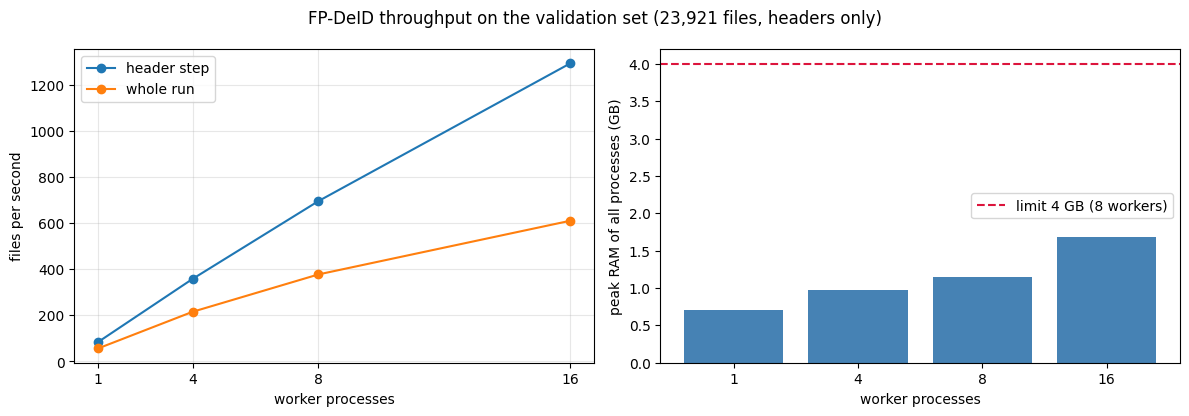

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.2))
axes[0].plot(speed_table["workers"], speed_table["files/s (header step)"], marker="o", label="header step")
axes[0].plot(speed_table["workers"], speed_table["files/s (whole run)"], marker="o", label="whole run")
axes[0].set_xlabel("worker processes")
axes[0].set_ylabel("files per second")
axes[0].set_xticks([1, 4, 8, 16])
axes[0].legend()
axes[0].grid(alpha=0.3)
axes[1].bar([str(w) for w in speed_table["workers"]], speed_table["peak RAM GB"], color="steelblue")
axes[1].axhline(4, color="crimson", linestyle="--", label="limit 4 GB (8 workers)")
axes[1].set_xlabel("worker processes")
axes[1].set_ylabel("peak RAM of all processes (GB)")
axes[1].legend()
plt.suptitle("FP-DeID throughput on the validation set (23,921 files, headers only)")
plt.tight_layout()
plt.savefig(os.path.join(phase_results, "benchmark.png"), dpi=110)
plt.show()

## 3. Determinism and lineage
The 8-worker and 16-worker runs must give byte-identical files (the number of workers must not matter), and every
output file must be traceable: its SHA-256 in the lineage must match the file on disk.

In [5]:
hashes_8 = output_hashes(os.path.join(bench_folder, "headers_w8"))
hashes_16 = output_hashes(os.path.join(bench_folder, "headers_w16"))
same_files = sum(1 for path in hashes_16 if hashes_8.get(path) == hashes_16[path])
print("identical output files (8 vs 16 workers):", same_files, "of", len(hashes_16))


def check_lineage_entry(entry):
    """True if the input and output files on disk have the SHA-256 written in the lineage."""
    ok_input = run.sha256_of_file(entry["input"]) == entry["input_sha256"]
    ok_output = run.sha256_of_file(entry["output"]) == entry["output_sha256"]
    complete = entry["policy_sha256"] != "" and entry["code_version"] != "" and entry["audit_line"] >= 1
    return ok_input and ok_output and complete


lineage_folder = os.path.join(bench_folder, "headers_w16")
with open(os.path.join(lineage_folder, "lineage.jsonl")) as f:
    lineage = [json.loads(line) for line in f]
with Pool(16) as pool:
    lineage_ok = pool.map(check_lineage_entry, lineage, chunksize=100)
output_files = glob.glob(os.path.join(lineage_folder, "*", "*", "*.dcm"))
lineage_pct = 100 * sum(lineage_ok) / len(output_files)
print("output files:", len(output_files), "| lineage lines:", len(lineage), "| correct and complete:",
      sum(lineage_ok), "=", round(lineage_pct, 3), "%")
pd.DataFrame(lineage[:2]).T

identical output files (8 vs 16 workers): 23921 of 23921


output files: 23921 | lineage lines: 23921 | correct and complete: 23921 = 100.0 %


,0,1
policy,policy.yaml,policy.yaml
policy_sha256,54e23b08d495907f56f189d100fab2c6b72db2761b1496a592b86bef926b132d,54e23b08d495907f56f189d100fab2c6b72db2761b1496a592b86bef926b132d
code_version,unknown,unknown
run_started,2026-10-27T21:21:19,2026-10-27T21:21:19
audit_line,1,2
audit_pixels_line,None,None
auditor_fix_lines,[],[]
input,/home/ayra2/ayra_data/midi_b/validation/images/1011144680/1.2.784.1.3.550561...,/home/ayra2/ayra_data/midi_b/validation/images/1014584441/2.5.428.0.3.585229...
input_sha256,6002cb4689d6f8a28152187e5116ab98fc723ab0d2a940e39acb7623af4cdd9e,5ceae4a2ed10758d0cf4c21036e955c5e659f8b495d1e7d073665821066af9d5
output,/home/ayra2/ayra_data/outputs/phase6/headers_w16/MIDI_1_1_122/1.3.6.1.4.1.14...,/home/ayra2/ayra_data/outputs/phase6/headers_w16/MIDI_1_1_016/1.3.6.1.4.1.14...


## 4. Resume: stop a run in the middle, start it again
The run is killed while it is cleaning headers. Started again with the same command, it must skip the files that
are done, clean the rest, and end with exactly the same files as a run that was never stopped.

In [6]:
resume_output = os.path.join(bench_folder, "resume")
shutil.rmtree(resume_output, ignore_errors=True)
command = command_for(resume_output, 16, ["--no-pixels", "--no-auditor"])
with open(resume_output + ".console.log", "w") as log:
    process = subprocess.Popen(command, stdout=log, stderr=subprocess.STDOUT, start_new_session=True)
    audit_path = os.path.join(resume_output, "audit.jsonl")
    while True:
        time.sleep(0.5)
        if os.path.exists(audit_path) and os.path.getsize(audit_path) > 20_000_000:
            break
    os.killpg(process.pid, signal.SIGKILL)
    process.wait()
with open(audit_path) as f:
    done_before_kill = sum(1 for line in f)
print("files in the audit log when the run was killed:", done_before_kill)

start = time.time()
with open(resume_output + ".console.log", "a") as log:
    subprocess.run(command, stdout=log, stderr=subprocess.STDOUT, check=True)
resume_seconds = time.time() - start
with open(os.path.join(resume_output, "run.log")) as f:
    resumed_line = [line.strip() for line in f if "already done" in line][-1]
print(resumed_line)

hashes_resumed = output_hashes(resume_output)
same_after_resume = sum(1 for path in hashes_16 if hashes_resumed.get(path) == hashes_16[path])
extra_files = len(glob.glob(os.path.join(resume_output, "*", "*", "*.dcm"))) - len(hashes_16)
print("identical to the uninterrupted run:", same_after_resume, "of", len(hashes_16), "| extra files:", extra_files)

files in the audit log when the run was killed: 1430


2026-10-27 21:22:35 INFO headers: 1430 files already done, 22491 to clean


identical to the uninterrupted run: 23921 of 23921 | extra files: 0


## 5. The full tool: headers + pixels (OCR on GPU 0) + auditor
Its output must be byte-identical to the Phase 5 output that was scored by the official scorer (99.831%).

In [7]:
full_output = os.path.join(bench_folder, "full")
full_summary = run_command(full_output, 16, [])
pd.Series(full_summary)

input                                   /home/ayra2/ayra_data/midi_b/validation/images
output                                       /home/ayra2/ayra_data/outputs/phase6/full
policy                                                 /home/ayra2/configs/policy.yaml
code_version                                                                   unknown
started                                                            2026-10-27T21:22:57
workers                                                                             16
files                                                                            23921
patients                                                                           216
seconds: fingerprints                                                             15.8
header errors                                                                        0
seconds: headers                                                                  18.7
files read by OCR                          

In [8]:
phase5_folder = os.path.join(paths.OUTPUTS, "phase5_validation")
hashes_full = output_hashes(full_output)
same_as_scored = 0
compared = 0
if os.path.exists(phase5_folder):
    for relative, digest in hashes_full.items():
        scored_file = os.path.join(phase5_folder, relative)
        if os.path.exists(scored_file):
            compared = compared + 1
            if run.sha256_of_file(scored_file) == digest:
                same_as_scored = same_as_scored + 1
print("files identical to the scored Phase 5 output:", same_as_scored, "of", compared)

full_rows = [{
    "step": "whole run, headers + OCR + auditor (16 workers, GPU 0)",
    "files": full_summary["files"],
    "seconds": full_summary["wall seconds"],
    "files/s": round(full_summary["files"] / full_summary["wall seconds"], 1),
    "studies/hour": round(3600 * n_studies / full_summary["wall seconds"]),
    "files read by OCR": full_summary["files read by OCR"],
    "peak RAM GB": full_summary["peak memory GB (all processes)"],
}]
for step in ["fingerprints", "headers", "pixels", "auditor", "lineage"]:
    full_rows.append({"step": "  " + step, "seconds": full_summary["seconds: " + step]})
full_table = pd.DataFrame(full_rows)
full_table.to_csv(os.path.join(phase_results, "benchmark_full.csv"), index=False)
full_table

files identical to the scored Phase 5 output: 23921 of 23921


,step,files,seconds,files/s,studies/hour,files read by OCR,peak RAM GB
0,"whole run, headers + OCR + auditor (16 workers, GPU 0)",23921.0,1787.4,13.4,485.0,710.0,3.78
1,fingerprints,NaN,15.8,NaN,NaN,NaN,NaN
2,headers,NaN,18.7,NaN,NaN,NaN,NaN
3,pixels,NaN,1682.5,NaN,NaN,NaN,NaN
4,auditor,NaN,64.5,NaN,NaN,NaN,NaN
5,lineage,NaN,3.8,NaN,NaN,NaN,NaN


## 6. Phase 6 summary vs. pass criteria

In [9]:
total_coverage = int(coverage_table[coverage_table["module"] == "TOTAL"]["coverage %"].iloc[0])
w8 = speed_table[speed_table["workers"] == 8].iloc[0]
w16 = speed_table[speed_table["workers"] == 16].iloc[0]
criteria = pd.DataFrame([
    ["tests pass", "100%, ≥ 40 tests", str(n_passed) + " passed, " + str(n_failed) + " failed, " +
     str(n_skipped) + " skipped"],
    ["code coverage of src/fpdeid", "≥ 80%", str(total_coverage) + "%"],
    ["throughput, headers only, 16 workers", "reported",
     str(w16["files/s (whole run)"]) + " files/s, " + str(int(w16["studies/hour (whole run)"])) + " studies/hour"],
    ["throughput, headers + OCR + auditor, 16 workers", "reported",
     str(full_rows[0]["files/s"]) + " files/s, " + str(full_rows[0]["studies/hour"]) + " studies/hour"],
    ["peak RAM with 8 workers", "≤ 4 GB", str(w8["peak RAM GB"]) + " GB"],
    ["identical output, 8 vs 16 workers", "100%", str(round(100 * same_files / len(hashes_16), 3)) + "%"],
    ["lineage correct and complete", "100%", str(round(lineage_pct, 3)) + "%"],
    ["resume after kill gives the same output", "100%",
     str(round(100 * same_after_resume / len(hashes_16), 3)) + "%, " + str(extra_files) + " extra files"],
    ["one-command output = scored Phase 5 output", "100%",
     str(round(100 * same_as_scored / max(1, compared), 3)) + "% of " + str(compared) + " files"],
], columns=["check", "target", "result"])
criteria.to_csv(os.path.join(phase_results, "pass_criteria.csv"), index=False)
criteria

,check,target,result
0,tests pass,"100%, ≥ 40 tests","62 passed, 0 failed, 0 skipped"
1,code coverage of src/fpdeid,≥ 80%,83%
2,"throughput, headers only, 16 workers",reported,"610.2 files/s, 22133 studies/hour"
3,"throughput, headers + OCR + auditor, 16 workers",reported,"13.4 files/s, 485 studies/hour"
4,peak RAM with 8 workers,≤ 4 GB,1.15 GB
5,"identical output, 8 vs 16 workers",100%,100.0%
6,lineage correct and complete,100%,100.0%
7,resume after kill gives the same output,100%,"100.0%, 0 extra files"
8,one-command output = scored Phase 5 output,100%,100.0% of 23921 files


## 7. Clean up (keep the small logs and summaries)

In [10]:
for name in sorted(os.listdir(bench_folder)):
    folder = os.path.join(bench_folder, name)
    if os.path.isdir(folder):
        summary_file = os.path.join(folder, "run_summary.json")
        if os.path.exists(summary_file):
            shutil.copy(summary_file, os.path.join(phase_results, "run_summary_" + name + ".json"))
shutil.copy(os.path.join(full_output, "run.log"), os.path.join(phase_results, "run_full.log"))
shutil.rmtree(bench_folder, ignore_errors=True)
print("benchmark outputs deleted")

benchmark outputs deleted
